# Learning a Stream with a Running Mean

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GalacticDynamics/phasecurvefit/blob/main/docs/tutorials/stream_runningmean.ipynb)

The [stream autoencoder tutorial](stream_autoencoder.ipynb) fits the mean
track of a stream with a trained decoder network. Training that decoder is most of
the cost. This tutorial fits the same stream with a **running mean** instead,
which has nothing to train: for any ordering coordinate $\gamma$ it averages the
positions of the member stars whose $\gamma$ falls within a small window around
it. Only the encoder is trained, so the fit is much faster (roughly ten times,
when we timed it), which matters when the fit sits inside a loop, such as a
likelihood evaluated at every step of an MCMC.

The price is accuracy: averaging along a curve pulls the path to the inside of
each bend. On a gently curving stream like this one the effect is small; the
[epitrochoid running-mean tutorial](epitrochoid_runningmean.ipynb) shows a case
where it is not, and explains the cause in detail.

In [1]:
import pathlib
import pickle

import equinox as eqx
import galax.coordinates as gc
import galax.dynamics as gd
import galax.potential as gp
import jax
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np

import quaxed.numpy as jnp
import unxt as u

import phasecurvefit as pcf

In [2]:
key = jr.key(201030)

## Data: a simulated stream

The same `galax` mock stream as the
[stream autoencoder tutorial](stream_autoencoder.ipynb), which describes the
simulation. It loads from the `mockstream.pkl` cache.

In [3]:
usys = u.unitsystems.galactic

# Progenitor Parameters
prog_w0 = gc.PhaseSpaceCoordinate(
    q=u.Q([10, 3, 5], "kpc"), p=u.Q([-4, 100, 4], "km/s"), t=u.Q(0.0, "Myr")
)
prog_mass = u.Quantity(2.5e4, "Msun")

# Stream Distribution Function
df = gd.FardalStreamDF()

# Potential
pot = gp.LMJ09LogarithmicPotential(
    v_c=u.Q(150, "km/s"),
    r_s=u.Q(2, "kpc"),
    q1=1.0,
    q2=1.3,
    q3=0.9,
    phi=u.Q(0, "deg"),
    units=usys,
)

# Mock stream generator (galax)
mockgen = gd.MockStreamGenerator(df, pot)

In [4]:
mockstream_path = pathlib.Path("mockstream.pkl")
mockstream_path.parent.mkdir(parents=True, exist_ok=True)

try:
    if mockstream_path.exists():
        with mockstream_path.open("rb") as handle:
            mockstream, prog = pickle.load(handle)  # noqa: S301
    else:
        raise FileNotFoundError(f"Missing {mockstream_path}")  # noqa: EM102, TRY003, TRY301
except Exception as exc:  # noqa: BLE001
    print(f"Loading failed ({exc!r}); running the simulation.")
    mockstream, prog = mockgen.run(
        key,
        u.Q(jnp.linspace(0, 4, 4_000), "Gyr"),
        prog_w0,
        prog_mass,
    )
    mockstream = jax.block_until_ready(mockstream)
    with mockstream_path.open("wb") as handle:
        pickle.dump((mockstream, prog), handle)

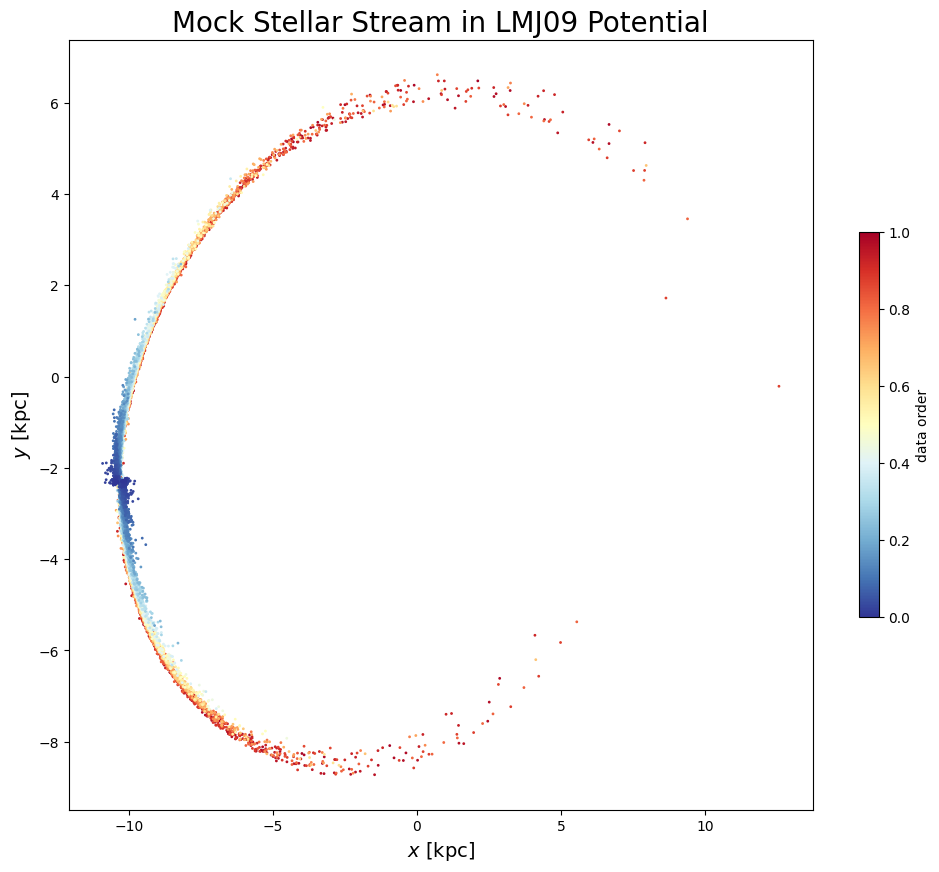

In [5]:
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111)
im = ax.scatter(
    np.array(mockstream.q.x),
    np.array(mockstream.q.y),
    s=1,
    c=jnp.linspace(1, 0, len(mockstream.q)),
    cmap="RdYlBu_r",
)
plt.colorbar(im, ax=ax, label="data order", shrink=0.5)
ax.set_xlabel(r"$x$ [kpc]", fontsize=14)
ax.set_ylabel(r"$y$ [kpc]", fontsize=14)
ax.set_title("Mock Stellar Stream in LMJ09 Potential", fontsize=20)
plt.show();

## Ordering with the local-flow walk

We shuffle the stars so their array order carries no information, then run the
same walk as the stream autoencoder tutorial, which explains each setting. It
orders a sparse but reliable subset of the stars.

In [6]:
# Shuffle the data
key, subkey = jr.split(key)
order = jr.permutation(subkey, jnp.arange(len(mockstream.q.x)))

qs = {k: getattr(mockstream.q, k)[order] for k in mockstream.q.components}
ps = {k: getattr(mockstream.p, k)[order] for k in mockstream.p.components}

In [7]:
# Determine the starting index as the point closest to the progenitor
# (a plain Python int: the walk is compiled around it).
start_idx = int(np.argmin(jnp.linalg.norm(mockstream.q[order] - prog.q, axis=1)))

# Walk configuration
config = pcf.WalkConfig(
    strategy=pcf.strats.KDTree(k=50),
    metric=pcf.metrics.AlignedMomentumDistanceMetric(),
)
metric_scale = u.Q(100, "kpc")
max_dist = u.Q(3, "kpc")


# Perform walk
walkresult = pcf.order(
    qs,
    ps,
    pcf.orderers.LocalFlowOrderer(
        start_idx=start_idx,
        metric_scale=metric_scale,
        max_dist=max_dist,
        config=config,
        direction="both",
    ),
    metadata=pcf.StateMetadata(usys=usys),
)
print(
    f"stars ordered by the walk: {int((walkresult.indices >= 0).sum())} of {len(order)}"
)

stars ordered by the walk: 248 of 8000


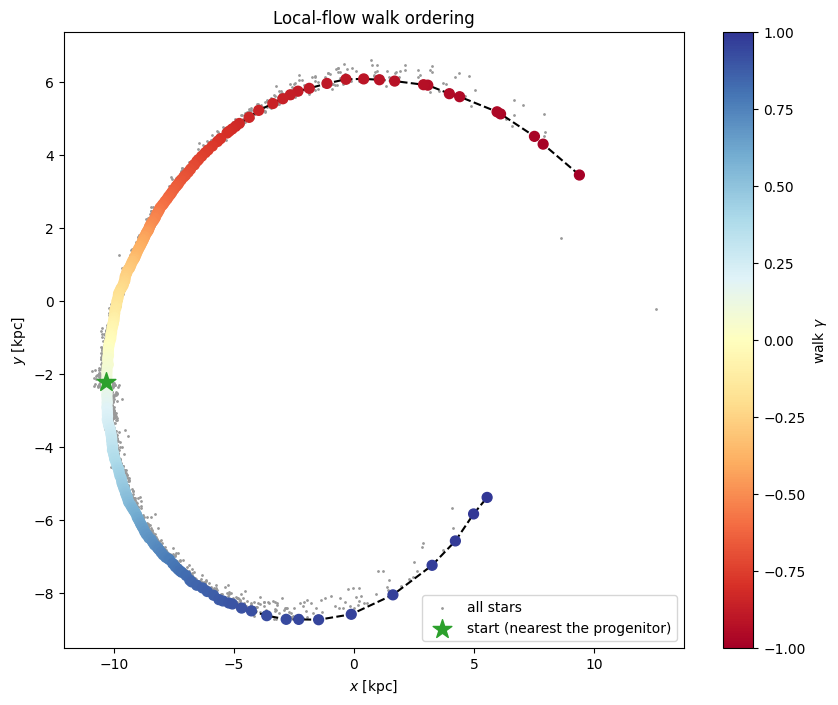

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(qs["x"], qs["y"], s=1, c="0.6", label="all stars")

ordering = walkresult.ordering
walk_qs = {k: v[ordering] for k, v in walkresult.positions.items()}
walk_gamma = np.linspace(*walkresult.gamma_range, len(ordering))
im = ax.scatter(walk_qs["x"], walk_qs["y"], s=50, c=walk_gamma, cmap="RdYlBu", zorder=3)
ax.plot(walk_qs["x"], walk_qs["y"], c="k", lw=1.5, ls="--", zorder=2)
ax.scatter(
    [qs["x"][start_idx]],
    [qs["y"][start_idx]],
    s=200,
    c="tab:green",
    marker="*",
    label="start (nearest the progenitor)",
    zorder=4,
)
fig.colorbar(im, ax=ax, label=r"walk $\gamma$")
ax.set(xlabel=r"$x$ [kpc]", ylabel=r"$y$ [kpc]", title="Local-flow walk ordering")
ax.legend()
plt.show()

## Training the encoder; building the running mean

`EncoderExternalDecoder` pairs a trainable encoder with a decoder that is not a
network:

- The **encoder** (`OrderingNet`) maps a star's 6 phase-space coordinates
  (`in_size=6`) to an ordering coordinate $\gamma$ and a membership probability
  $p$. It is trained on the walk's ordering, as in phase 1 of the full
  autoencoder.
- The **decoder** (`RunningMeanDecoder`) is filled in after training. It stores
  every star's encoder $\gamma$ and position, and answers a query $\gamma$ with
  the mean position of the member stars ($p > 0.5$) within `window_size / 2` of
  it.

In [9]:
key, model_key, train_key = jr.split(key, 3)
normalizer = pcf.nn.StandardScalerNormalizer(qs, ps)
model = pcf.nn.EncoderExternalDecoder(
    encoder=pcf.nn.OrderingNet(in_size=6, key=model_key),
    decoder=pcf.nn.RunningMeanDecoder(window_size=0.05),
    normalizer=normalizer,
)
result, opt_state, losses = pcf.nn.train_autoencoder(model, walkresult, key=train_key)

Training:   0%|          | 0/800 [00:00<?, ?epoch/s]

## Result

Within half a window of either tip there are stars on one side only, so the
average there is pulled back towards the stream's interior. We evaluate the path
only where the window is full.

In [10]:
def running_mean_path(result, window_size, n=2_000):
    """Evaluate the running-mean path with a given window, away from the tips."""
    result_w = eqx.tree_at(lambda r: r.model.decoder.window_size, result, window_size)
    g_train = result_w.model.decoder.gamma_train
    lo = float(g_train.min()) + window_size / 2
    hi = float(g_train.max()) - window_size / 2
    return result_w(jnp.linspace(lo, hi, n))

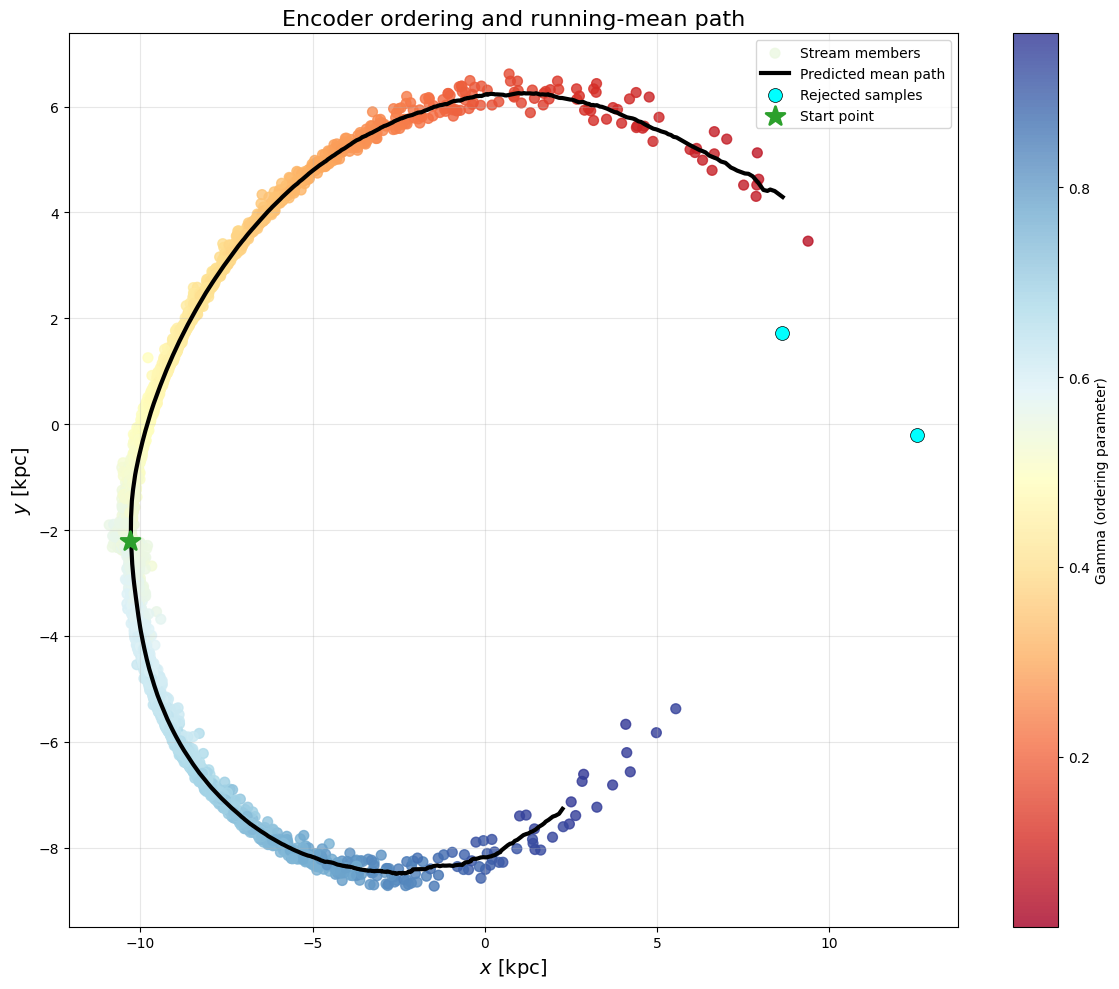

In [11]:
fig, ax = plt.subplots(figsize=(12, 10))

all_gamma, all_probs = result.model.encode(walkresult.positions, walkresult.velocities)
rejected_membership = all_probs < 0.5  # the running mean's member threshold
qs_pred = running_mean_path(result, window_size=0.05)

# Plot all points with gradient coloring
im = ax.scatter(
    np.asarray(qs["x"]),
    np.asarray(qs["y"]),
    s=50,
    c=np.asarray(all_gamma),
    cmap="RdYlBu",
    alpha=0.8,
    label="Stream members",
)

# Plot predicted mean path
ax.plot(
    np.asarray(qs_pred["x"]),
    np.asarray(qs_pred["y"]),
    c="k",
    lw=3,
    label="Predicted mean path",
)

# Mark rejected samples in cyan
ax.scatter(
    np.asarray(qs["x"][rejected_membership]),
    np.asarray(qs["y"][rejected_membership]),
    s=100,
    c="cyan",
    alpha=1.0,
    marker="o",
    edgecolors="black",
    linewidths=0.5,
    label="Rejected samples",
)

# Mark start point
ax.scatter(
    np.asarray(qs["x"][start_idx]),
    np.asarray(qs["y"][start_idx]),
    s=200,
    c="tab:green",
    marker="*",
    label="Start point",
    linewidths=2,
    zorder=5,
)

ax.set_xlabel(r"$x$ [kpc]", fontsize=14)
ax.set_ylabel(r"$y$ [kpc]", fontsize=14)
ax.set_title("Encoder ordering and running-mean path", fontsize=16)
fig.colorbar(im, ax=ax, label="Gamma (ordering parameter)")
ax.legend(loc="upper right", fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show();

**What to look for:** the colour (the encoder's $\gamma$) changes smoothly
from tip to tip, and the path runs along the middle of the stream. Unlike on the
[epitrochoid](epitrochoid_runningmean.ipynb), there is little visible offset: this
stream bends gently compared with the window, so the stars within one window lie
on a nearly straight segment, and their average stays on the stream. Where the
stream is sparse, near the tips, fewer stars share each window and the path gets
noisier.

## Takeaways

- The running mean replaces decoder training with a windowed average, and is
  roughly ten times faster to fit than the full autoencoder here.
- Its accuracy depends on the window size relative to the stream's curvature and
  density. For gently curving streams the default works well; for tightly curved
  ones, see the [epitrochoid running-mean tutorial](epitrochoid_runningmean.ipynb).